# Predicción de compra en una red social
## Preprocesamiento, análisis exploratorio y regresión logística

**Dataset:** `Social_Network_Ads.csv` · **Asignatura:** Inteligencia Artificial · **Grupo_6:** Mario Ibañez Lorenzo Torres Pablo Piqueras

El objetivo es estudiar la asociación de la edad, el salario estimado y el género con la compra de un producto anunciado, y comparar modelos de regresión logística capaces de predecir `Purchased` (0 = no compra; 1 = compra). Los resultados describen asociaciones predictivas; no prueban que una característica cause la compra ni que un anuncio sea eficaz.

**Contenido:** 1. Reproducibilidad · 2. Auditoría · 3. Partición · 4. EDA · 5. Preparación y modelos · 6. Validación cruzada y selección · 7. Evaluación final · 8. Visualización e interpretación · 9. Conclusiones.

**Cómo ejecutarlo:** guardar el CSV proporcionado junto a este notebook y seleccionar **Reiniciar kernel y ejecutar todas las celdas**. En Google Colab, subir también el CSV al panel de archivos. El notebook ya contiene las salidas de una ejecución completa. La semilla es 42 y el umbral de clasificación es 0,5.

## 1. Entorno y reproducibilidad

Se usan pandas y NumPy para preparar los datos, Matplotlib y seaborn para los gráficos, y scikit-learn para el aprendizaje. La siguiente celda opcional instala las dependencias si faltan.

In [1]:
# Ejecutar solo si faltan dependencias (quitar el símbolo # de la línea siguiente):
# %pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk

SEED = 42
UMBRAL = 0.5
sns.set_theme(style='whitegrid', context='notebook', palette=['#64748b', '#be123c'])
COLORES_COMPRA = {'No compra': '#64748b', 'Compra': '#be123c'}
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)

## 2. Carga y auditoría del dataset

La auditoría de integridad se realiza sobre el archivo completo. Después se separa Test, antes de explorar asociaciones con la compra. Así, las decisiones sobre variables y transformaciones se basan en Train.

| Variable | Significado | Papel |
|---|---|---|
| User ID | Identificador del usuario | Comprobación de identidad; excluido del modelo |
| Gender | Categoría Male/Female presente en el archivo | Predictor categórico |
| Age | Edad en años | Predictor numérico |
| EstimatedSalary | Salario anual estimado; moneda no especificada | Predictor numérico |
| Purchased | 0 = no compra; 1 = compra | Objetivo binario |

In [3]:
df_original = pd.read_csv('Social_Network_Ads.csv')
df = df_original.copy()
print('Dimensiones:', df.shape)
display(df.head(8))
df.info()
display(pd.DataFrame({'tipo': df.dtypes.astype(str),
                      'nulos': df.isna().sum(),
                      'valores_distintos': df.nunique()}))

Dimensiones: (400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
5,15728773,Male,27,58000,0
6,15598044,Female,27,84000,0
7,15694829,Female,32,150000,1


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


,tipo,nulos,valores_distintos
User ID,int64,0,400
Gender,str,0,2
Age,int64,0,43
EstimatedSalary,int64,0,117
Purchased,int64,0,2


In [4]:
columnas_esperadas = ['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased']
assert df.columns.tolist() == columnas_esperadas, 'Revisar las columnas del CSV.'

auditoria = pd.Series({
    'Valores nulos': int(df.isna().sum().sum()),
    'Filas completas duplicadas': int(df.duplicated().sum()),
    'Identificadores repetidos': int(df['User ID'].duplicated().sum()),
    'Perfiles repetidos sin User ID (incluye objetivo)': int(df.drop(columns='User ID').duplicated().sum()),
    'Gender fuera de Male/Female': int((~df['Gender'].isin(['Male', 'Female'])).sum()),
    'Purchased fuera de 0/1': int((~df['Purchased'].isin([0, 1])).sum()),
    'Edades no plausibles (<0 o >120)': int((~df['Age'].between(0, 120)).sum()),
    'Edades no enteras': int((df['Age'] % 1 != 0).sum()),
    'Salarios negativos': int((df['EstimatedSalary'] < 0).sum()),
    'Valores numéricos no finitos': int((~np.isfinite(df.select_dtypes('number'))).sum().sum())
}, name='Recuento')
display(auditoria.to_frame())
display(df[['Age', 'EstimatedSalary']].agg(['min', 'max']))
display(df['Gender'].value_counts().rename('Usuarios').to_frame())
balance_global = df['Purchased'].value_counts().sort_index().to_frame('usuarios')
balance_global['porcentaje'] = 100 * balance_global['usuarios'] / len(df)
display(balance_global)

# Estas comprobaciones impiden seguir silenciosamente con datos inválidos.
assert df.notna().all().all()
assert df['User ID'].is_unique
assert df['Gender'].isin(['Female', 'Male']).all()
assert df['Purchased'].isin([0, 1]).all()
assert df['Age'].between(0, 120).all() and (df['Age'] % 1 == 0).all()
assert (df['EstimatedSalary'] >= 0).all()
assert np.isfinite(df.select_dtypes('number')).all().all()

,Recuento
Valores nulos,0
Filas completas duplicadas,0
Identificadores repetidos,0
Perfiles repetidos sin User ID (incluye objetivo),20
Gender fuera de Male/Female,0
Purchased fuera de 0/1,0
Edades no plausibles (<0 o >120),0
Edades no enteras,0
Salarios negativos,0
Valores numéricos no finitos,0


,Age,EstimatedSalary
min,18,15000
max,60,150000


,Usuarios
Gender,
Female,204
Male,196


,usuarios,porcentaje
Purchased,,
0,257,64.25
1,143,35.75


**Interpretación y limpieza.** Hay **400 filas y 5 columnas**, sin nulos, duplicados completos ni identificadores repetidos. No es necesaria una imputación y no se elimina ninguna fila. Las edades están entre 18 y 60 años y los salarios entre 15 000 y 150 000, sin valores imposibles según las reglas comprobadas. Que un valor sea plausible no garantiza que se haya medido correctamente: no se dispone de documentación externa para validarlo.

Existen **20 repeticiones adicionales de perfiles sin el ID**, contando también la compra. Se conservan: distintos IDs pueden tener la misma edad, salario y género, y no hay evidencia de que representen al mismo usuario. Se asume una observación independiente por usuario. Si hubiera usuarios o hogares relacionados, habría que revisar esta suposición y dividir por grupos.

Hay **257 no compradores (64,25 %) y 143 compradores (35,75 %)**. El desbalance es moderado: predecir siempre «no compra» ya lograría un 64,25 % de aciertos en el archivo completo, pero un Recall de compradores igual a cero. Se estratifica la división y se incluye un modelo de referencia. El efecto de ponderar las clases se comprueba mediante validación cruzada; no se aplica sobremuestreo de forma automática.

## 3. Codificación y separación de Train/Test

Se elimina `User ID` de los predictores porque identifica un registro y no representa una característica explicativa del cliente. `Gender` se codifica como **Female = 0; Male = 1**. Esta codificación fija no estima parámetros ni introduce una jerarquía entre categorías; con dos categorías basta una sola variable indicadora.

Se reserva el **25 % para Test** (100 usuarios) y el **75 % para Train** (300 usuarios), manteniendo aproximadamente las proporciones de compra mediante `stratify`. El EDA detallado y la selección se hacen exclusivamente con Train. Test se utiliza al final, una vez fijado el modelo.

In [5]:
datos = df.drop(columns='User ID').copy()
datos['Gender'] = datos['Gender'].map({'Female': 0, 'Male': 1}).astype(int)
X = datos.drop(columns='Purchased')
y = datos['Purchased']
X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(df)

particion = pd.DataFrame({
    'Total': [len(y_train), len(y_test)],
    'No compra': [(y_train == 0).sum(), (y_test == 0).sum()],
    'Compra': [y_train.sum(), y_test.sum()],
    '% compra': [100 * y_train.mean(), 100 * y_test.mean()]
}, index=['Train', 'Test'])
display(particion)
eda = X_train.join(y_train)
eda['Compra'] = eda['Purchased'].map({0: 'No compra', 1: 'Compra'})
eda['Género'] = eda['Gender'].map({0: 'Female', 1: 'Male'})

,Total,No compra,Compra,% compra
Train,300,193,107,35.6667
Test,100,64,36,36.0000


## 4. Análisis exploratorio sobre Train
### 4.1. Estadísticas descriptivas y valores extremos

Se comparan las distribuciones globales de Train y las de compradores/no compradores. La regla del rango intercuartílico (IQR) señala observaciones para revisión, pero no demuestra que sean errores.

In [6]:
display(eda[['Age', 'EstimatedSalary', 'Purchased']].describe().T)
display(eda.groupby('Compra')[['Age', 'EstimatedSalary']].agg(['mean', 'median', 'std', 'min', 'max']))
display(eda.groupby('Género')['Purchased'].agg(usuarios='size', compradores='sum', tasa_compra='mean'))

filas_iqr = []
for variable in ['Age', 'EstimatedSalary']:
    q1, q3 = X_train[variable].quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    extremos = ~X_train[variable].between(inferior, superior)
    filas_iqr.append({'Variable': variable, 'Límite inferior': inferior,
                      'Límite superior': superior, 'Fuera de límites': int(extremos.sum())})
tabla_iqr = pd.DataFrame(filas_iqr)
display(tabla_iqr)

,count,mean,std,min,25%,50%,75%,max
Age,300.0,37.1400,10.6269,18.0,28.0,36.5,46.0,60.0
EstimatedSalary,300.0,70903.3333,35221.7152,15000.0,43000.0,71000.0,88250.0,150000.0
Purchased,300.0,0.3567,0.4798,0.0,0.0,0.0,1.0,1.0


Age                        EstimatedSalary           \
              mean median     std min max            mean   median   
Compra                                                               
Compra     46.0093   47.0  8.7884  27  60      90345.7944  96000.0   
No compra  32.2228   32.0  8.0672  18  59      60124.3523  60000.0   

                                      
                  std    min     max  
Compra                                
Compra     41737.5228  20000  150000  
No compra  25352.2081  15000  141000

,usuarios,compradores,tasa_compra
Género,,,
Female,162,58,0.3580
Male,138,49,0.3551


,Variable,Límite inferior,Límite superior,Fuera de límites
0,Age,1.0,73.0,0
1,EstimatedSalary,-24875.0,156125.0,0


### 4.2. Distribuciones, desbalance y comparación por grupos

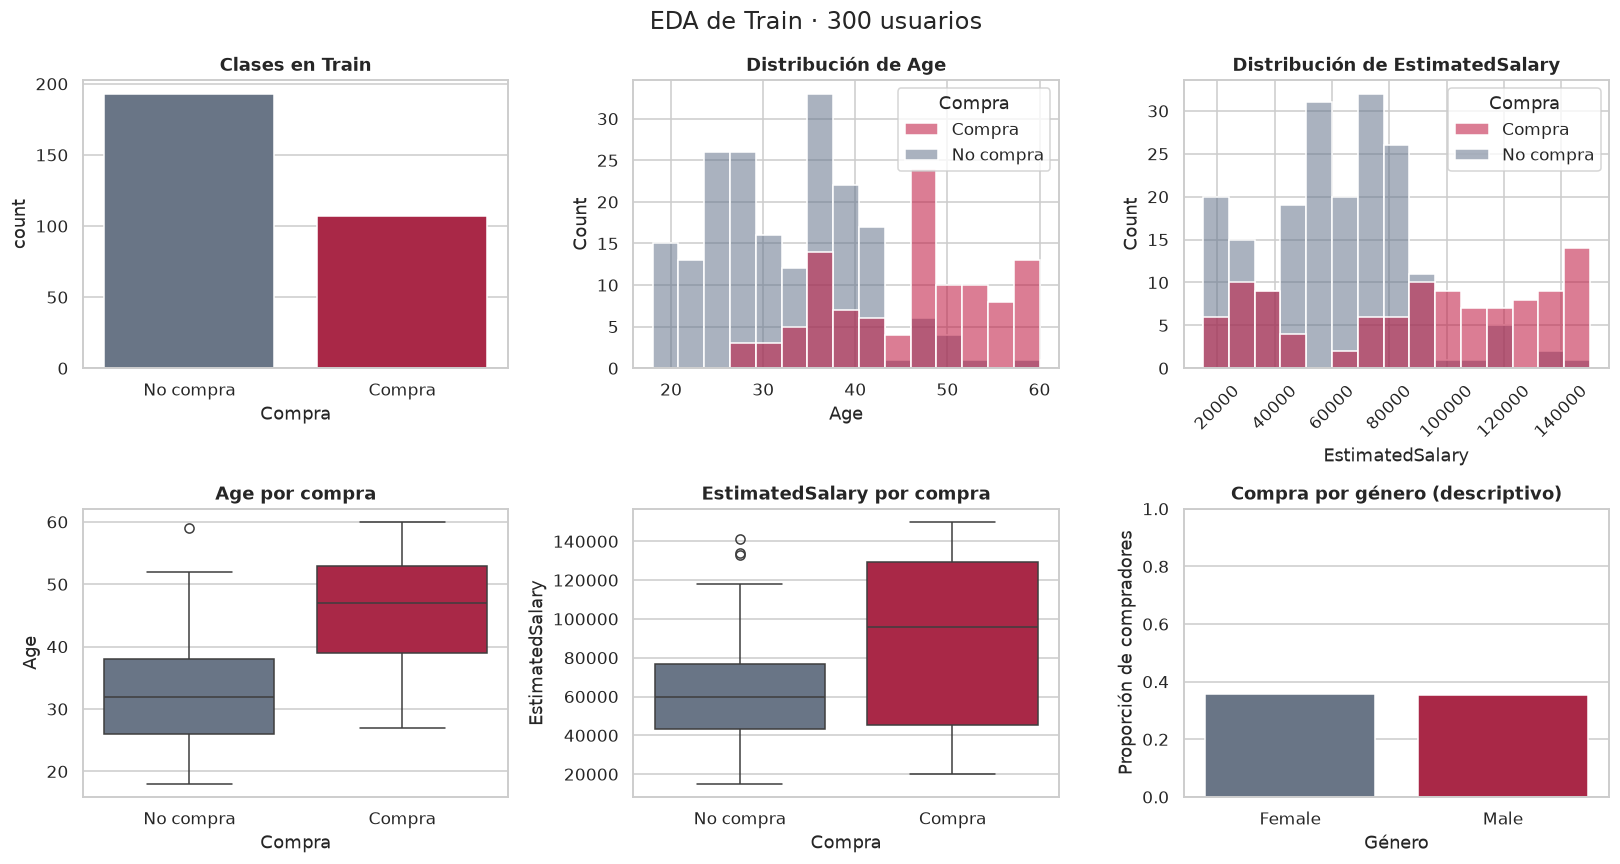

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(data=eda, x='Compra', hue='Compra', order=['No compra', 'Compra'],
               palette=COLORES_COMPRA, legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Clases en Train')
for ax, variable in zip(axes[0, 1:], ['Age', 'EstimatedSalary']):
    sns.histplot(data=eda, x=variable, hue='Compra', bins=15, palette=COLORES_COMPRA,
                 multiple='layer', alpha=0.55, ax=ax)
    ax.set_title(f'Distribución de {variable}')
for ax, variable in zip(axes[1, :2], ['Age', 'EstimatedSalary']):
    sns.boxplot(data=eda, x='Compra', y=variable, hue='Compra', order=['No compra', 'Compra'],
                palette=COLORES_COMPRA, legend=False, ax=ax)
    ax.set_title(f'{variable} por compra')
sns.barplot(data=eda, x='Género', y='Purchased', errorbar=None,
            hue='Género', legend=False, ax=axes[1, 2])
axes[1, 2].set_ylim(0, 1)
axes[1, 2].set_ylabel('Proporción de compradores')
axes[1, 2].set_title('Compra por género (descriptivo)')
axes[0, 2].tick_params(axis='x', labelrotation=45)
fig.suptitle('EDA de Train · 300 usuarios', fontsize=16)
plt.tight_layout()
plt.show()

**Lectura de las distribuciones.** En Train, quienes compran tienen una edad media de **46,01 años**, frente a **32,22** entre quienes no compran. El salario medio es **90345,79**, frente a **60124,35**, respectivamente. Esto sugiere estudiar edad y salario como predictores, pero las distribuciones se solapan: ninguna media permite clasificar a todos los usuarios sin error.

Las tasas de compra por género son muy próximas: **35,80 % en Female y 35,51 % en Male**. No se observa una diferencia marginal descriptiva importante en Train. Se comprueba su aportación en los modelos, sin concluir a partir de esta tabla que su efecto sea exactamente nulo.

La regla IQR aplicada a cada variable en todo Train no señala ningún valor extremo. Los boxplots por clase pueden marcar puntos fuera de sus bigotes porque utilizan cuartiles específicos de cada clase. Esto no contradice el cálculo global. Se conservan todas las observaciones: no hay evidencia suficiente para recortar salarios o eliminar usuarios.

### 4.3. Correlación y pairplot

La correlación de Pearson mide asociaciones lineales. Con una variable binaria equivale a la correlación punto-biserial; no demuestra causalidad. `User ID` se excluye también de esta matriz. El pairplot permite detectar patrones que una única correlación podría ocultar.

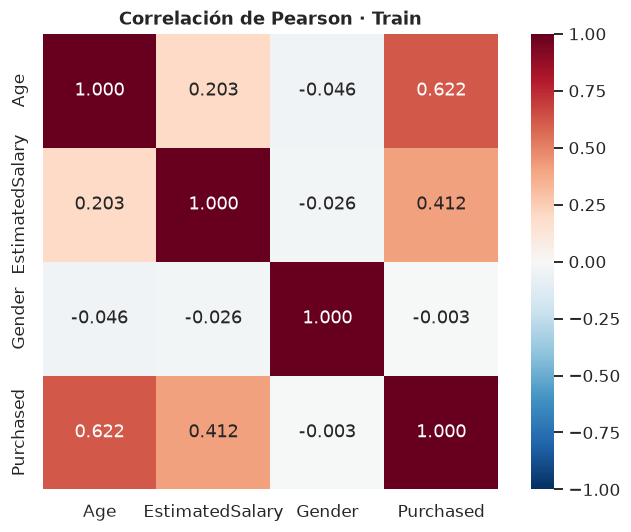

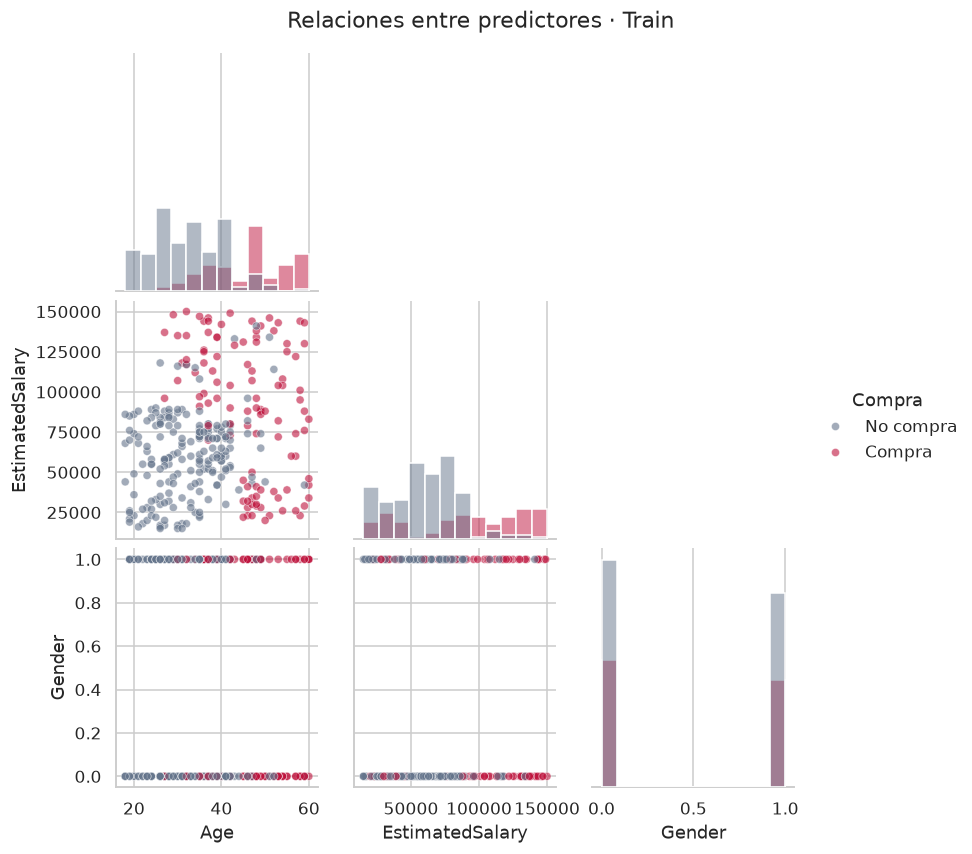

In [8]:
correlaciones = eda[['Age', 'EstimatedSalary', 'Gender', 'Purchased']].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(correlaciones, annot=True, fmt='.3f', cmap='RdBu_r',
            vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title('Correlación de Pearson · Train')
plt.tight_layout()
plt.show()

grafico = sns.pairplot(eda, vars=['Age', 'EstimatedSalary', 'Gender'], hue='Compra',
                       hue_order=['No compra', 'Compra'], palette=COLORES_COMPRA,
                       diag_kind='hist', corner=True,
                       plot_kws={'alpha': 0.6, 's': 28}, diag_kws={'bins': 12})
grafico.fig.suptitle('Relaciones entre predictores · Train', y=1.03)
plt.show()

**Interpretación.** En Train, la asociación lineal con compra es mayor para edad (**r = 0,622**) que para salario (**r = 0,412**). La correlación de género con compra es prácticamente cero (**r = -0,003**). Edad y salario tienen una correlación de **0,203**, que no apunta a una redundancia lineal fuerte entre ambos.

En el pairplot se observan compradores de edad elevada en distintos niveles salariales, junto con compradores más jóvenes con salarios altos. Esto motiva comparar una frontera lineal con una interacción y una expansión cuadrática. No se fija una regla determinista a partir del gráfico: existen casos solapados. La fila correspondiente a Gender contiene bandas porque es una variable binaria, no continua.

## 5. Preparación y modelos candidatos
### 5.1. Estandarización y prevención de fugas de información

La edad está expresada en decenas de años, mientras que el salario está en decenas de miles. Se estandarizan ambas variables: $z=(x-\mu_{Train})/\sigma_{Train}$. Esto mejora la optimización y evita que el salario domine solo por su escala. `Gender`, ya binaria, se mantiene como 0/1.

Cada modelo contiene su preprocesamiento en un `Pipeline`. En cada partición de validación cruzada, los escaladores se ajustan **solo con el subconjunto de entrenamiento de esa partición**. En el ajuste final se estiman con todo Train y se aplican a Test sin volver a ajustarlos. No se escala todo el dataset antes de dividirlo.

Para los modelos polinómicos se estandarizan las variables originales, se generan los términos y se estandarizan también los términos resultantes. Así, un cuadrado o un producto no queda en una escala dominante. La expansión solo afecta a edad y salario: no se añade `Gender²`, que duplicaría `Gender`.

### 5.2. Qué estima una regresión logística

El modelo estima $P(Y=1\mid X)=1/(1+e^{-\eta})$, donde $\eta=\beta_0+\beta_1x_1+\cdots+\beta_px_p$. Se predice compra cuando la probabilidad es mayor o igual a **0,5**.

En el modelo con interacción se incluyen $z_{edad}$, $z_{salario}$ y $z_{edad}z_{salario}$. En el cuadrático se añaden también $z_{edad}^2$ y $z_{salario}^2$. **Siguen siendo regresiones logísticas**, aunque su frontera en el plano edad-salario pueda ser curva.

Se usa la regresión logística con la configuración por defecto de scikit-learn. Se limita el grado a 2 para contener la complejidad con solo 300 observaciones de Train. Se incluyen variantes con `class_weight='balanced'` para comprobar si compensar el desbalance mejora la identificación de compradores.

In [9]:
# Cada candidato especifica sus variables, transformación y ponderación.
configuraciones = {
    'M1': {'nombre': 'Género', 'num': [], 'genero': True, 'grado': 1, 'interaccion': False, 'peso': None},
    'M2': {'nombre': 'Edad', 'num': ['Age'], 'genero': False, 'grado': 1, 'interaccion': False, 'peso': None},
    'M3': {'nombre': 'Salario', 'num': ['EstimatedSalary'], 'genero': False, 'grado': 1, 'interaccion': False, 'peso': None},
    'M4': {'nombre': 'Edad + salario', 'num': ['Age', 'EstimatedSalary'], 'genero': False, 'grado': 1, 'interaccion': False, 'peso': None},
    'M5': {'nombre': 'Edad + salario + género', 'num': ['Age', 'EstimatedSalary'], 'genero': True, 'grado': 1, 'interaccion': False, 'peso': None},
    'M6': {'nombre': 'Edad × salario (con efectos principales)', 'num': ['Age', 'EstimatedSalary'], 'genero': False, 'grado': 2, 'interaccion': True, 'peso': None},
    'M7': {'nombre': 'Edad + salario, cuadrático', 'num': ['Age', 'EstimatedSalary'], 'genero': False, 'grado': 2, 'interaccion': False, 'peso': None},
    'M8': {'nombre': 'Cuadrático + género', 'num': ['Age', 'EstimatedSalary'], 'genero': True, 'grado': 2, 'interaccion': False, 'peso': None},
    'M9': {'nombre': 'Edad + salario, balanceado', 'num': ['Age', 'EstimatedSalary'], 'genero': False, 'grado': 1, 'interaccion': False, 'peso': 'balanced'},
    'M10': {'nombre': 'Cuadrático, balanceado', 'num': ['Age', 'EstimatedSalary'], 'genero': False, 'grado': 2, 'interaccion': False, 'peso': 'balanced'}
}

def crear_modelo(config):
    transformadores = []
    if len(config['num']) > 0:
        pasos = [('escala_original', sk.preprocessing.StandardScaler())]
        if config['grado'] == 2:
            pasos.append(('polinomios', sk.preprocessing.PolynomialFeatures(
                degree=2, include_bias=False, interaction_only=config['interaccion'])))
            pasos.append(('escala_terminos', sk.preprocessing.StandardScaler()))
        transformadores.append(('numericas', sk.pipeline.Pipeline(pasos), config['num']))
    if config['genero']:
        transformadores.append(('genero', 'passthrough', ['Gender']))
    preparacion = sk.compose.ColumnTransformer(transformadores, remainder='drop', verbose_feature_names_out=False)
    return sk.pipeline.Pipeline([
        ('preparacion', preparacion),
        ('logistica', sk.linear_model.LogisticRegression(solver='lbfgs', max_iter=5000,
                                         class_weight=config['peso'], random_state=SEED))
    ])

display(pd.DataFrame(configuraciones).T.rename(columns={
    'nombre': 'Descripción', 'num': 'Numéricas', 'genero': 'Incluye género',
    'grado': 'Grado', 'interaccion': 'Solo interacción', 'peso': 'Peso de clases'}))

,Descripción,Numéricas,Incluye género,Grado,Solo interacción,Peso de clases
M1,Género,[],True,1,False,None
M2,Edad,[Age],False,1,False,None
M3,Salario,[EstimatedSalary],False,1,False,None
M4,Edad + salario,"[Age, EstimatedSalary]",False,1,False,None
M5,Edad + salario + género,"[Age, EstimatedSalary]",True,1,False,None
M6,Edad × salario (con efectos principales),"[Age, EstimatedSalary]",False,2,True,None
M7,"Edad + salario, cuadrático","[Age, EstimatedSalary]",False,2,False,None
M8,Cuadrático + género,"[Age, EstimatedSalary]",True,2,False,None
M9,"Edad + salario, balanceado","[Age, EstimatedSalary]",False,1,False,balanced
M10,"Cuadrático, balanceado","[Age, EstimatedSalary]",False,2,False,balanced


## 6. Validación cruzada y selección usando exclusivamente Train
### 6.1. Métricas y criterio fijado antes de evaluar Test

La clase positiva es **compra (1)**. A partir de la matriz de confusión se calculan:

| Métrica | Definición | Interpretación para marketing |
|---|---|---|
| Exactitud (Accuracy) | $(TP+TN)/N$ | Proporción total de usuarios bien clasificados |
| Sensibilidad (Recall) | $TP/(TP+FN)$ | De los compradores reales, cuántos detecta el modelo |
| Especificidad | $TN/(TN+FP)$ | De los no compradores reales, cuántos reconoce como tales |
| Precisión (Precision) | $TP/(TP+FP)$ | De los que el modelo señala como compradores, cuántos compran |
| F1 | $2PR/(P+R)$ | Resumen de Precisión y Sensibilidad; solo informativo |

**Qué error importa más.** Un **falso negativo** es un comprador potencial al que no se le muestra el anuncio: es una venta perdida. Un **falso positivo** es un usuario que recibe el anuncio sin llegar a comprar: cuesta una impresión publicitaria. Para marketing es más grave perder compradores que enseñar el anuncio a alguien de más. Por eso se **prioriza la Sensibilidad**, aceptando algunos falsos positivos para reducir los falsos negativos. Como la Sensibilidad sola se podría maximizar marcando a todo el mundo, **se desempata por Exactitud**, y se vigilan la Especificidad y la Precisión para comprobar que el número de falsas alarmas sigue siendo razonable.

Se emplean **5 particiones estratificadas repetidas 3 veces (15 evaluaciones)**. Todos los candidatos comparten las mismas particiones. Se selecciona el modelo con mayor Sensibilidad media; en empate, el de mayor Exactitud media y, si aún empatan, el de menos términos. El umbral 0,5 permanece fijo y no se optimiza en Test.

Las desviaciones típicas describen la variación entre particiones; no son intervalos de confianza, porque las particiones repetidas no son independientes. Al elegir el modelo con la misma validación, su resultado puede ser algo optimista. **Test reservado es la evaluación final independiente del modelo seleccionado**; no se presenta la CV como una evaluación anidada.

In [10]:
cv = sk.model_selection.RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
particiones_cv = list(cv.split(X_train, y_train))
metricas_cv = {'accuracy': 'accuracy', 'recall': 'recall',
               'especificidad': sk.metrics.make_scorer(sk.metrics.recall_score, pos_label=0),
               'precision': sk.metrics.make_scorer(sk.metrics.precision_score, zero_division=0),
               'f1': 'f1'}

modelos_ajustados = {}
filas_cv = []
for identificador, config in configuraciones.items():
    modelo = crear_modelo(config)
    resultado = sk.model_selection.cross_validate(modelo, X_train, y_train,
                                                  scoring=metricas_cv, cv=particiones_cv)
    modelos_ajustados[identificador] = modelo.fit(X_train, y_train)
    terminos = modelo.named_steps['preparacion'].get_feature_names_out()
    fila = {'Modelo': identificador, 'Descripción': config['nombre'], 'N términos': len(terminos)}
    for metrica in metricas_cv:
        fila[f'{metrica}_media'] = resultado[f'test_{metrica}'].mean()
        fila[f'{metrica}_sd'] = resultado[f'test_{metrica}'].std()
    filas_cv.append(fila)

tabla_cv = pd.DataFrame(filas_cv).set_index('Modelo')
# Mayor Sensibilidad media; en empate, mayor Exactitud media y menos términos.
orden_cv = tabla_cv.reset_index().sort_values(
    ['recall_media', 'accuracy_media', 'N términos', 'Modelo'], ascending=[False, False, True, True])
elegido = orden_cv.iloc[0]['Modelo']
modelo_final = modelos_ajustados[elegido]
display(tabla_cv.loc[orden_cv['Modelo'], ['Descripción', 'N términos',
        'recall_media', 'recall_sd', 'accuracy_media', 'especificidad_media', 'precision_media', 'f1_media']])
print('MODELO FIJADO ANTES DE EVALUAR TEST:', elegido, configuraciones[elegido]['nombre'])

,Descripción,N términos,recall_media,recall_sd,accuracy_media,especificidad_media,precision_media,f1_media
Modelo,,,,,,,,
M10,"Cuadrático, balanceado",5,0.9043,0.0695,0.9022,0.9016,0.8404,0.8687
M7,"Edad + salario, cuadrático",5,0.8701,0.0685,0.9000,0.9172,0.8590,0.8614
M8,Cuadrático + género,6,0.8700,0.0667,0.9011,0.9189,0.8609,0.8628
M9,"Edad + salario, balanceado",2,0.8505,0.0669,0.8511,0.8517,0.7646,0.8025
M6,Edad × salario (con efectos principales),3,0.8296,0.0738,0.8789,0.9068,0.8350,0.8300
M4,Edad + salario,2,0.6918,0.0808,0.8411,0.9239,0.8373,0.7553
M5,Edad + salario + género,3,0.6886,0.0843,0.8411,0.9256,0.8397,0.7537
M2,Edad,1,0.6545,0.0943,0.8300,0.9274,0.8392,0.7303
M3,Salario,1,0.4811,0.0940,0.7833,0.9518,0.8620,0.6080


MODELO FIJADO ANTES DE EVALUAR TEST: M10 Cuadrático, balanceado


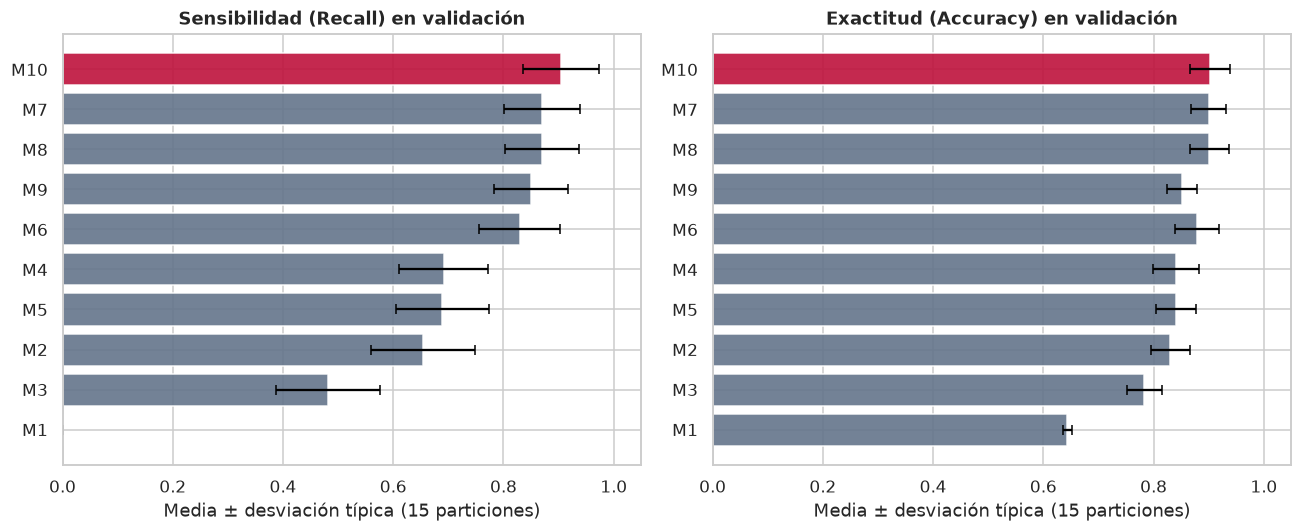

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
orden = orden_cv['Modelo'].tolist()[::-1]
for ax, metrica, titulo in zip(axes, ['recall', 'accuracy'], ['Sensibilidad (Recall) en validación', 'Exactitud (Accuracy) en validación']):
    valores = tabla_cv.loc[orden]
    colores = ['#be123c' if m == elegido else '#64748b' for m in orden]
    ax.barh(orden, valores[f'{metrica}_media'], xerr=valores[f'{metrica}_sd'],
             color=colores, alpha=0.9, capsize=3)
    ax.set_xlim(0, 1.05)
    ax.set_title(titulo)
    ax.set_xlabel('Media ± desviación típica (15 particiones)')
plt.tight_layout()
plt.show()

**Selección fijada: M10, Cuadrático, balanceado.** Obtiene la mayor Sensibilidad media de CV: **90,43 % ± 6,95**, y además la mayor Exactitud (**90,22 %**), con Especificidad **90,16 %** y Precisión **84,04 %**. Detecta más compradores que el resto sin pagarlo con muchas más falsas alarmas.

La comparación permite justificar las decisiones:

- **Variables individuales:** edad (M2, Sensibilidad = 65,45 %) supera a salario (M3, 48,11 %). Género por sí solo (M1) tiene Sensibilidad 0 %: predice siempre «no compra», igual que la clase mayoritaria (Exactitud 64,33 %, Especificidad 100 %).
- **Combinación y curvatura:** edad + salario (M4) detecta el 69,18 % de los compradores. Añadir la interacción (M6) sube al 82,96 %, y el cuadrático (M7) al 87,01 %. Es el inconveniente de la regresión logística que asume una relación lineal: con términos cuadráticos y de interacción la frontera puede ser curva y separa mejor las clases. La flexibilidad se justifica por la mejora en validación, no solo por el ajuste sobre Train.
- **Género:** añadirlo no mejora la Sensibilidad: en el lineal baja de 69,18 % a 68,86 %, y en el cuadrático se queda igual (87,01 % → 87,00 %). El modelo elegido no lo usa. No se demuestra que carezca de toda asociación, sino que no ayuda a predecir aquí.
- **Ponderación:** frente a M7, M10 aumenta la Sensibilidad de 87,01 % a 90,43 %, mientras la Especificidad pasa de 91,72 % a 90,16 % y la Precisión de 85,90 % a 84,04 %. En el modelo lineal la ponderación (M9) también sube la Sensibilidad, pero hunde la Especificidad al 85,17 %: compensa en el cuadrático, no en el lineal.

La ventaja de Sensibilidad de M10 sobre M7 es de **3,42 puntos porcentuales**, pequeña frente a la variabilidad entre particiones (≈ 7 puntos). La regla de selección conduce a M10, pero no se trata de una superioridad estadística concluyente; M7 es una alternativa razonable. No se cambia el criterio tras consultar Test.

## 7. Evaluación final en Train y Test
### 7.1. Comparación de todos los modelos

Cada candidato ya está reajustado con todo Train mediante `refit`. Se calculan las métricas de Train por resustitución: son descriptivas del ajuste, no una medida independiente de generalización. Test contiene usuarios no utilizados para ajustar los modelos.

Para cumplir la comparación del enunciado se muestran también los resultados Test de todas las alternativas. **La selección anterior se mantiene aunque otra alternativa obtenga una cifra Test superior.** Comparar repetidamente alternativas y elegir después por Test invalidaría su función de evaluación final.

In [12]:
def evaluar_modelo(modelo, X_datos, y_datos):
    probabilidades = modelo.predict_proba(X_datos)[:, 1]
    predicciones = (probabilidades >= UMBRAL).astype(int)
    tn, fp, fn, tp = sk.metrics.confusion_matrix(y_datos, predicciones, labels=[0, 1]).ravel()
    return {'Accuracy': sk.metrics.accuracy_score(y_datos, predicciones),
            'Recall': sk.metrics.recall_score(y_datos, predicciones, zero_division=0),
            'Precision': sk.metrics.precision_score(y_datos, predicciones, zero_division=0),
            'Especificidad': tn / (tn + fp),
            'F1': sk.metrics.f1_score(y_datos, predicciones, zero_division=0),
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

filas_evaluacion = []
for nombre, modelo in modelos_ajustados.items():
    for conjunto, X_datos, y_datos in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        filas_evaluacion.append({'Modelo': nombre, 'Conjunto': conjunto,
                                 **evaluar_modelo(modelo, X_datos, y_datos)})
resultados = pd.DataFrame(filas_evaluacion).set_index(['Modelo', 'Conjunto'])
display(resultados[['Accuracy', 'Recall', 'Especificidad', 'Precision', 'F1']].unstack('Conjunto'))
print('Matrices en forma de recuentos (TN, FP, FN, TP):')
display(resultados[['TN', 'FP', 'FN', 'TP']])

Accuracy          Recall         Especificidad         Precision  \
Conjunto     Test   Train    Test   Train          Test   Train      Test   
Modelo                                                                      
M1           0.64  0.6433  0.0000  0.0000        1.0000  1.0000    0.0000   
M10          0.89  0.9067  0.8611  0.9159        0.9062  0.9016    0.8378   
M2           0.87  0.8300  0.7500  0.6542        0.9375  0.9275    0.8710   
M3           0.76  0.7833  0.3889  0.4766        0.9688  0.9534    0.8750   
M4           0.84  0.8467  0.6667  0.7103        0.9375  0.9223    0.8571   
M5           0.81  0.8567  0.6111  0.7196        0.9219  0.9326    0.8148   
M6           0.88  0.8833  0.8056  0.8411        0.9219  0.9067    0.8529   
M7           0.91  0.8967  0.8611  0.8692        0.9375  0.9119    0.8857   
M8           0.89  0.9000  0.8611  0.8692        0.9062  0.9171    0.8378   
M9           0.80  0.8567  0.7778  0.8598        0.8125  0.8549    0.7000   

                      F1          
Conjunto   Train    Test   Train  
Modelo                            
M1        0.0000  0.0000  0.0000  
M10       0.8376  0.8493  0.8750  
M2        0.8333  0.8060  0.7330  
M3        0.8500  0.5385  0.6108  
M4        0.8352  0.7500  0.7677  
M5        0.8556  0.6984  0.7817  
M6        0.8333  0.8286  0.8372  
M7        0.8455  0.8732  0.8571  
M8        0.8532  0.8493  0.8611  
M9        0.7667  0.7368  0.8106

Matrices en forma de recuentos (TN, FP, FN, TP):


TN  FP   FN  TP
Modelo Conjunto                  
M1     Train     193   0  107   0
       Test       64   0   36   0
M2     Train     179  14   37  70
       Test       60   4    9  27
M3     Train     184   9   56  51
       Test       62   2   22  14
M4     Train     178  15   31  76
       Test       60   4   12  24
M5     Train     180  13   30  77
       Test       59   5   14  22
M6     Train     175  18   17  90
       Test       59   5    7  29
M7     Train     176  17   14  93
       Test       60   4    5  31
M8     Train     177  16   14  93
       Test       58   6    5  31
M9     Train     165  28   15  92
       Test       52  12    8  28
M10    Train     174  19    9  98
       Test       58   6    5  31

### 7.2. Matrices de confusión

En todas las matrices, las filas son la clase real y las columnas la predicha: arriba izquierda TN, arriba derecha FP, abajo izquierda FN y abajo derecha TP. La escala de color es común dentro de cada figura para facilitar la comparación.

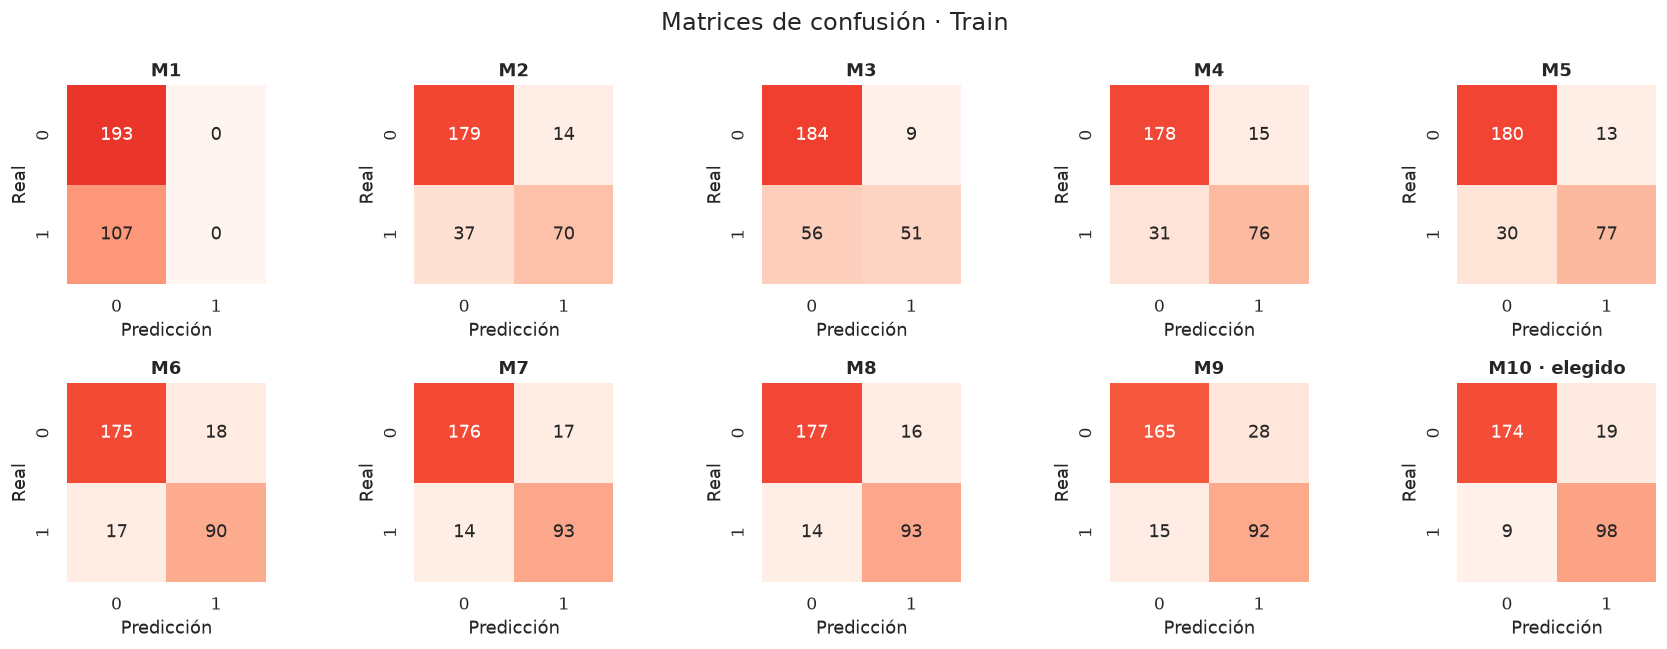

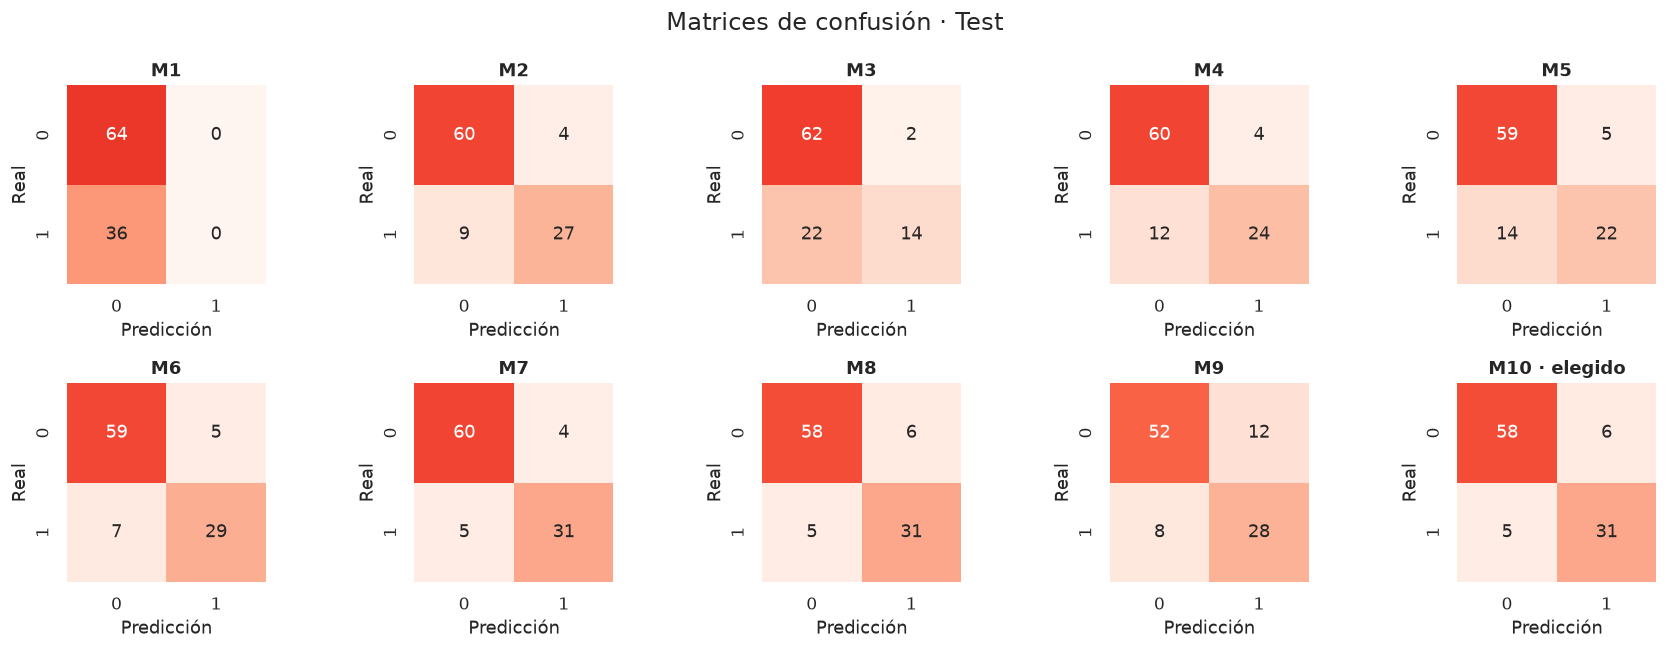

In [13]:
for conjunto, X_datos, y_datos in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
    fig, axes = plt.subplots(2, 5, figsize=(16, 6))
    for ax, nombre in zip(axes.flat, configuraciones):
        predicciones = (modelos_ajustados[nombre].predict_proba(X_datos)[:, 1] >= UMBRAL).astype(int)
        matriz = sk.metrics.confusion_matrix(y_datos, predicciones, labels=[0, 1])
        sns.heatmap(matriz, annot=True, fmt='d', cmap='Reds', cbar=False,
                    vmin=0, vmax=len(y_datos), square=True, ax=ax,
                    xticklabels=['0', '1'], yticklabels=['0', '1'])
        ax.set_title(nombre + (' · elegido' if nombre == elegido else ''))
        ax.set_xlabel('Predicción')
        ax.set_ylabel('Real')
    fig.suptitle(f'Matrices de confusión · {conjunto}', fontsize=16)
    plt.tight_layout()
    plt.show()

**Resultado del modelo elegido (M10).** En Train obtiene Exactitud **90,67 %**, Sensibilidad **91,59 %** y Especificidad **90,16 %**. En Test obtiene Exactitud **89,00 %**, Sensibilidad **86,11 %**, Especificidad **90,62 %** y Precisión **83,78 %**.

Su matriz Test es **TN = 58, FP = 6, FN = 5, TP = 31**. Es decir, identifica **31 de los 36 compradores**, deja escapar 5 y clasifica erróneamente como compradores a 6 de los 64 no compradores. Seleccionaría a 37 usuarios, de los que 31 compran en este conjunto. Exactitud = (58 + 31)/100 = 89 %, Sensibilidad = 31/36 = 86,11 % y Especificidad = 58/64 = 90,62 %. La referencia mayoritaria solo alcanza un 64 % de Accuracy y no detecta ningún comprador.

Comparando las matrices de Train y Test, la Exactitud baja **1,67 puntos porcentuales**, la Sensibilidad 5,48 y la Especificidad se mantiene. Junto a la CV, esto no sugiere overfitting fuerte, aunque no permite descartar sobreajuste con una sola muestra Test de 100 usuarios.

**La mejor cifra Test no cambia la selección.** M7 alcanza un 91 % de Exactitud y un 93,75 % de Especificidad, algo por encima de M10 en este conjunto: detecta los mismos 31 compradores, pero produce 4 FP en lugar de 6. Se mantiene M10 porque se eligió antes por CV. Elegir ahora M7 por su Test convertiría Test en otro conjunto de selección. Esta discrepancia muestra la incertidumbre de comparar modelos cercanos con pocas observaciones.

El salario aislado también muestra inestabilidad: su Sensibilidad pasa de 48,11 % en CV a 38,89 % en Test. Su utilidad es mayor al combinarlo con edad y términos no lineales que como predictor único.

### 7.3. Justificación de cada modelo según la teoría

**Regla de decisión (tema 3, *Análisis del performance*).**
1. **Qué error importa más.** Perder un comprador (FN) es una venta perdida; mostrar el anuncio a quien no compra (FP) cuesta poco. Como en el ejemplo de detección de COVID del tema, se aceptan algunos falsos positivos para reducir los falsos negativos: se **prioriza la Sensibilidad**.
2. **Desempate por Exactitud**, vigilando Especificidad y Precisión para que las falsas alarmas no se disparen.
3. **Overfitting:** se comparan las matrices de confusión de Train y Test.

Cifras de validación cruzada sobre Train, que es con lo que se decide:

| Modelo | Sensibilidad | Exactitud | Especificidad | Precisión | Veredicto |
|---|---|---|---|---|---|
| M1 Género | 0 % | 64,33 % | 100 % | 0 % | Descartado |
| M2 Edad | 65,45 % | 83,00 % | 92,74 % | 83,92 % | Descartado |
| M3 Salario | 48,11 % | 78,33 % | 95,18 % | 86,20 % | Descartado |
| M4 Edad + salario | 69,18 % | 84,11 % | 92,39 % | 83,73 % | Descartado |
| M5 Edad + salario + género | 68,86 % | 84,11 % | 92,56 % | 83,97 % | Descartado |
| M6 Interacción edad×salario | 82,96 % | 87,89 % | 90,68 % | 83,50 % | Descartado |
| M7 Cuadrático | 87,01 % | 90,00 % | 91,72 % | 85,90 % | Alternativa |
| M8 Cuadrático + género | 87,00 % | 90,11 % | 91,89 % | 86,09 % | Descartado |
| M9 Lineal balanceado | 85,05 % | 85,11 % | 85,17 % | 76,46 % | Descartado |
| **M10 Cuadrático balanceado** | **90,43 %** | **90,22 %** | 90,16 % | 84,04 % | **Elegido** |

**Por qué se descarta o se acepta cada uno:**

- **M1 · Género, descartado.** Es el caso que advierte el tema: *la exactitud por sí sola puede ocultar errores*. Tiene 64 % de Exactitud y 100 % de Especificidad, pero no detecta ningún comprador: siempre predice «no compra», igual que la clase mayoritaria. El EDA ya lo anticipaba: compra el 35,8 % de las mujeres y el 35,5 % de los hombres (r = −0,003).
- **M2 · Edad, descartado.** Es la mejor variable individual (r = 0,62 en el EDA) y tiene buena Exactitud, pero deja escapar a 1 de cada 3 compradores. Con la Sensibilidad como prioridad no es suficiente.
- **M3 · Salario, descartado.** Detecta menos de la mitad de los compradores (48 %) y es inestable: en Test baja al 39 %. Su Especificidad del 95 % es alta solo porque casi nunca predice «compra».
- **M4 · Edad + salario lineal, descartado.** Combinar ambas mejora, pero se queda en el 69 %. Es el inconveniente que señala el tema: la regresión logística *asume una relación lineal*. El pairplot muestra compradores mayores y también jóvenes con salario alto, algo que una recta no separa bien.
- **M5 · Añadir género, descartado.** La Sensibilidad no mejora, incluso baja (69,18 % → 68,86 %): una variable más sin beneficio.
- **M6 · Interacción, descartado, pero clave.** Al añadir el término edad×salario la Sensibilidad salta del 69 % al 83 %. Esto demuestra que la relación no es lineal y justifica usar en $z = b + f(x_1, x_2^2, \dots)$ términos no lineales. Lo superan los cuadráticos.
- **M7 · Cuadrático, alternativa.** Con edad² y salario² llega al 87,01 % de Sensibilidad y al 90 % de Exactitud. Es muy bueno, pero M10 detecta más compradores.
- **M8 · Cuadrático + género, descartado.** El género no aporta nada (87,01 % → 87,00 % de Sensibilidad): más complejidad sin mejora.
- **M9 · Lineal balanceado, descartado.** `class_weight='balanced'` da más peso a los compradores por ser la clase minoritaria. En el lineal sube la Sensibilidad (69 % → 85 %), pero la Especificidad cae al 85 % y la Precisión al 76 %: demasiadas falsas alarmas. El tema acepta *algunos* falsos positivos, no tantos.
- **M10 · Cuadrático balanceado, elegido.** Mayor Sensibilidad (90,43 %) y también mayor Exactitud (90,22 %). La ponderación cuesta poco: la Especificidad pasa de 91,72 % (M7) a 90,16 %. La curva cuadrática ya separa bien las clases y el peso extra recupera compradores sin disparar las falsas alarmas.

**Comprobación final en Test (M10).** Matriz TN = 58, FP = 6, FN = 5, TP = 31: detecta 31 de los 36 compradores, con Exactitud 89 %, Sensibilidad 86,11 % y Especificidad 90,62 %. Al comparar las matrices de Train y Test, como indica el tema, la Exactitud baja solo 1,7 puntos (90,67 % → 89 %) y la Especificidad se mantiene: no hay overfitting fuerte. Encaja con la ventaja de la regresión logística de que *no es común sufrir overfitting salvo con muchas variables y pocos datos*; por eso se limita el grado a 2 (solo cinco términos).

**Matiz.** M10 supera a M7 en 3,4 puntos de Sensibilidad, pero la variación entre particiones es de unos 7 puntos: la regla elige M10, aunque M7 es casi igual de bueno. En Test M7 obtiene incluso algo más de Exactitud (91 % frente a 89 %), pero no se cambia de modelo: elegir mirando Test convertiría Test en otro conjunto de selección.

## 8. Predicciones e interpretación de variables
### 8.1. Probabilidades predichas de todos los modelos en Train

Cada punto es un usuario de Train. El eje horizontal indica su clase real, con un pequeño desplazamiento para que los puntos se vean; el vertical es la probabilidad predicha de compra. La línea discontinua es el umbral 0,5. Los puntos de clase 0 por encima de la línea son FP; los de clase 1 por debajo son FN. Estas figuras ilustran el ajuste sobre Train y deben leerse junto a CV y Test.

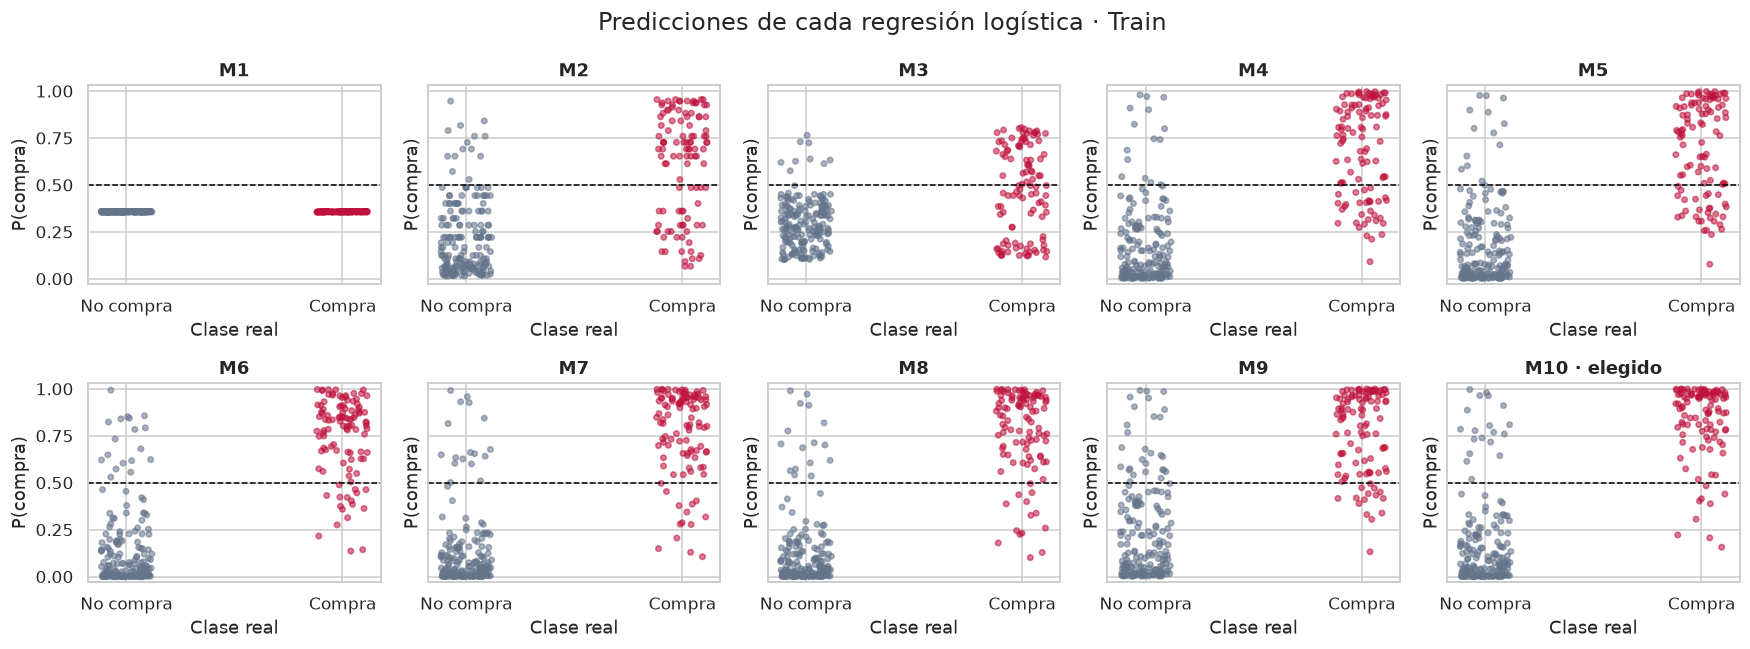

In [14]:
rng = np.random.default_rng(SEED)
jitter = rng.uniform(-0.12, 0.12, len(y_train))
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharey=True)
for ax, nombre in zip(axes.flat, configuraciones):
    probabilidades = modelos_ajustados[nombre].predict_proba(X_train)[:, 1]
    ax.scatter(y_train.to_numpy() + jitter, probabilidades,
               c=np.where(y_train.to_numpy() == 1, '#be123c', '#64748b'), s=13, alpha=0.55)
    ax.axhline(UMBRAL, color='black', linestyle='--', linewidth=1)
    ax.set_xticks([0, 1], ['No compra', 'Compra'])
    ax.set_ylim(-0.03, 1.03)
    ax.set_title(nombre + (' · elegido' if nombre == elegido else ''))
    ax.set_xlabel('Clase real')
    ax.set_ylabel('P(compra)')
fig.suptitle('Predicciones de cada regresión logística · Train', fontsize=16)
plt.tight_layout()
plt.show()

### 8.2. Fronteras en el plano edad-salario

Se representan cuatro candidatos que dependen exclusivamente de edad y salario: lineal, interacción, cuadrático y cuadrático balanceado. El fondo es P(compra), el contorno negro marca 0,5 y el color de los puntos indica la clase real. No se fijan artificialmente otras variables para estas fronteras. Las zonas sin puntos tienen menos apoyo empírico y no deben interpretarse como perfiles bien validados.

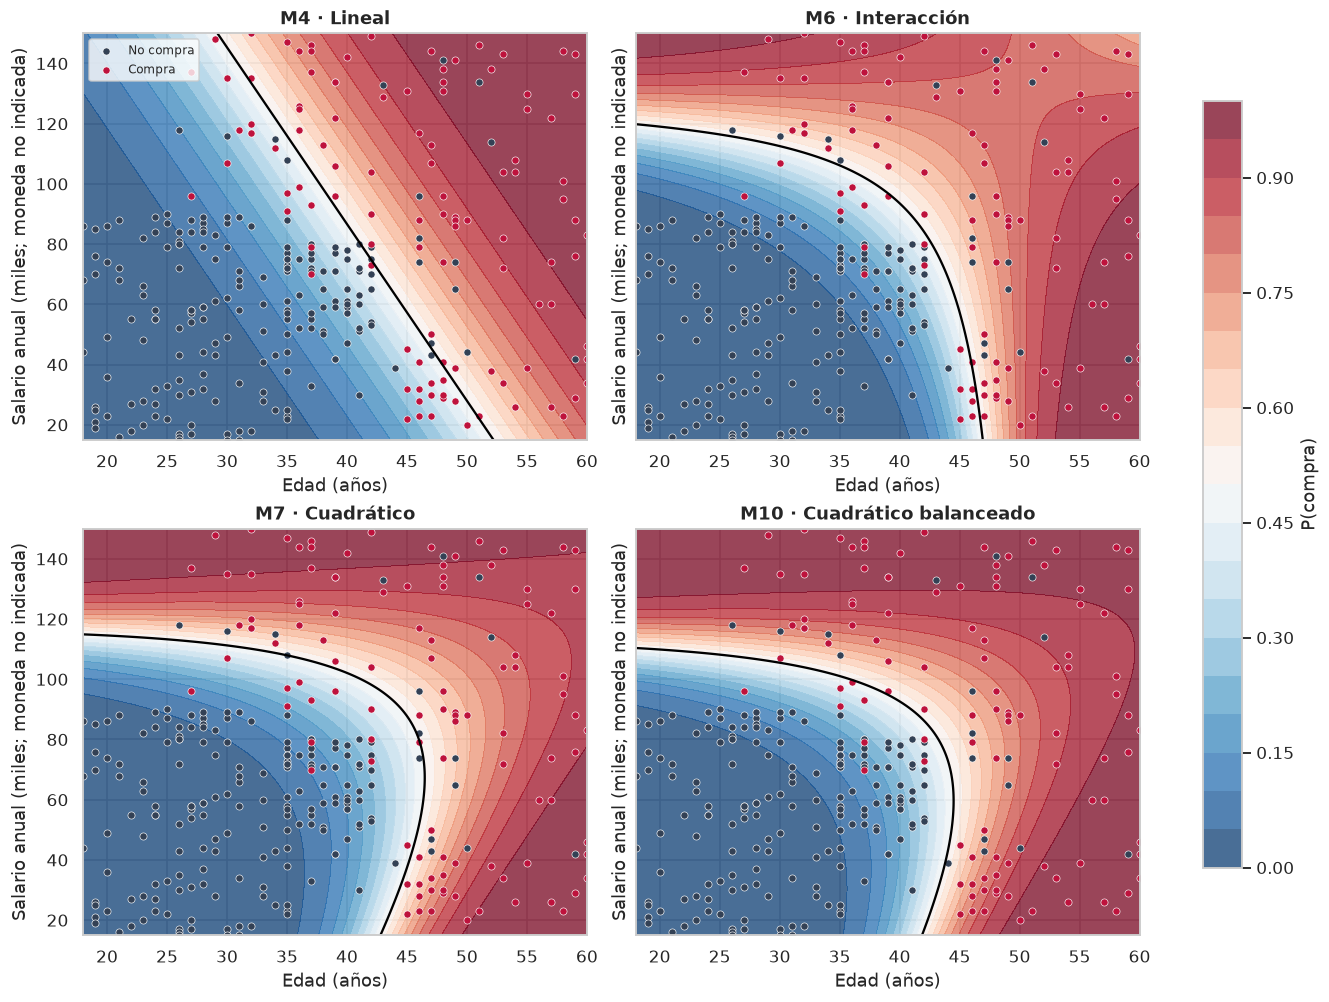

In [15]:
edades = np.linspace(X_train['Age'].min(), X_train['Age'].max(), 180)
salarios = np.linspace(X_train['EstimatedSalary'].min(), X_train['EstimatedSalary'].max(), 180)
xx, yy = np.meshgrid(edades, salarios)
rejilla = pd.DataFrame({'Age': xx.ravel(), 'EstimatedSalary': yy.ravel(), 'Gender': 0})
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True, layout='constrained')
for ax, nombre in zip(axes.flat, ['M4', 'M6', 'M7', 'M10']):
    superficie = modelos_ajustados[nombre].predict_proba(rejilla)[:, 1].reshape(xx.shape)
    fondo = ax.contourf(xx, yy / 1000, superficie, levels=np.linspace(0, 1, 21), cmap='RdBu_r', alpha=0.75)
    ax.contour(xx, yy / 1000, superficie, levels=[0.5], colors='black', linewidths=1.5)
    for clase, color in [(0, '#334155'), (1, '#be123c')]:
        mascara = y_train == clase
        ax.scatter(X_train.loc[mascara, 'Age'], X_train.loc[mascara, 'EstimatedSalary'] / 1000,
                   c=color, s=22, edgecolor='white', linewidth=0.4,
                   label='Compra' if clase else 'No compra')
    ax.set_title(nombre + ' · ' + {'M4': 'Lineal', 'M6': 'Interacción', 'M7': 'Cuadrático',
                                  'M10': 'Cuadrático balanceado'}[nombre])
    ax.set_xlabel('Edad (años)')
    ax.set_ylabel('Salario anual (miles; moneda no indicada)')
axes[0, 0].legend(fontsize=8)
fig.colorbar(fondo, ax=axes.ravel().tolist(), label='P(compra)', shrink=0.85)
plt.show()

La regresión lineal en los predictores impone una recta como frontera. La interacción permite que la relación del salario con la compra cambie según la edad. El modelo cuadrático puede representar curvaturas adicionales. Una frontera más flexible solo se justifica si mejora la validación; dibujar una curva que encaje con Train no basta.

### 8.3. Coeficientes y aportación predictiva

Se muestran los coeficientes del modelo lineal con todas las variables (M5) como referencia interpretable, y los términos del modelo elegido. En M5, `exp(coeficiente)` es la razón de *odds* (probabilidad de compra dividida entre probabilidad de no compra) por una desviación típica más de edad/salario, manteniendo el resto fijo; para `Gender` compara Male frente a Female. No es un aumento directo de probabilidad.

En un modelo con cuadrados o interacciones, el coeficiente de edad aislado no resume su efecto: también cambian los términos en los que interviene. Por ello la contribución predictiva se valora principalmente mediante los candidatos de CV y las fronteras, no mediante una ordenación ingenua de coeficientes. Los coeficientes no son pruebas de significación estadística.

In [16]:
def tabla_coeficientes(modelo):
    nombres = modelo.named_steps['preparacion'].get_feature_names_out()
    coeficientes = modelo.named_steps['logistica'].coef_[0]
    return pd.DataFrame({'Término': nombres, 'Coeficiente': coeficientes})

coef_lineales = tabla_coeficientes(modelos_ajustados['M5'])
coef_lineales['Odds ratio'] = np.exp(coef_lineales['Coeficiente'])
print('M5: lineal con edad, salario y género')
display(coef_lineales)
print('Intercepto M5:', round(float(modelos_ajustados['M5'].named_steps['logistica'].intercept_[0]), 4))
print('Términos del modelo elegido:', elegido)
display(tabla_coeficientes(modelo_final))
print('Intercepto elegido:', round(float(modelo_final.named_steps['logistica'].intercept_[0]), 4))

M5: lineal con edad, salario y género


,Término,Coeficiente,Odds ratio
0,Age,2.1637,8.7036
1,EstimatedSalary,1.2144,3.3682
2,Gender,0.3129,1.3674


Intercepto M5: -1.2804
Términos del modelo elegido: M10


,Término,Coeficiente
0,Age,2.3793
1,EstimatedSalary,1.5040
2,Age^2,0.1029
3,Age EstimatedSalary,-1.5277
4,EstimatedSalary^2,0.8951


Intercepto elegido: -1.0813


**Interpretación del modelo lineal de referencia.** Los coeficientes de edad y salario son positivos. En M5, un incremento de una desviación típica de edad se asocia con multiplicar las odds por aproximadamente **8,70**, manteniendo salario y género constantes; para salario, el factor es **3,37**. Son asociaciones condicionadas al modelo y no efectos causales ni multiplicadores directos de probabilidad.

Para Male frente a Female, M5 estima una razón de odds de **1,37** al ajustar por edad y salario. Esto puede coexistir con tasas marginales de compra muy parecidas: una asociación ajustada no es la misma que una diferencia global entre grupos. Sin intervalos de los coeficientes ni pruebas específicas no se afirma significación estadística. Además, que añadir género no mejore la CV aconseja no tratarlo como una variable decisiva.

La evidencia conjunta del EDA y de los modelos indica que **edad y salario aportan la mayor señal predictiva**, con una relación que una recta no recoge completamente. En el modelo elegido deben interpretarse conjuntamente los términos lineales, cuadrados e interacción.

## 9. Conclusiones y límites

1. **Datos preparados.** Se mantienen las 400 observaciones: no hay nulos ni duplicados del mismo identificador. Se elimina `User ID` como predictor, se codifica género y se estandarizan las variables numéricas dentro de cada pipeline. La división estratificada deja 300 usuarios en Train y 100 en Test.
2. **Qué características ayudan a predecir.** Edad es la variable individual más informativa; combinarla con salario mejora el resultado. Género añade muy poco en CV. Los patrones observados son asociaciones, no explicaciones causales de la compra.
3. **Modelo seleccionado.** Entre diez regresiones logísticas se selecciona **M10: edad y salario con expansión cuadrática, ponderación balanced**, por su mayor Sensibilidad media de validación (90,43 %), que además va acompañada de la mayor Exactitud (90,22 %). Tiene cinco términos predictivos y un intercepto. La diferencia con los otros cuadráticos es modesta y no se presenta como una superioridad concluyente.
4. **Evaluación final.** Con umbral 0,5, logra en Test **89,00 % de Exactitud, 86,11 % de Sensibilidad, 90,62 % de Especificidad y 83,78 % de Precisión**. Detecta 31 compradores, omite 5 y genera 6 falsas alarmas. Supera ampliamente la referencia mayoritaria, cuya Sensibilidad es cero.
5. **Decisión para marketing.** Se prioriza la Sensibilidad porque perder un comprador cuesta más que mostrar el anuncio a alguien que no compra. La ponderación mejora la detección de compradores en CV casi sin perder Especificidad ni Precisión. No puede afirmarse que maximice el beneficio de una campaña. M7 obtiene mejores cifras en este Test, pero se mantiene la selección previa para no utilizar Test como otro conjunto de ajuste.

**Alcance.** Son 400 observaciones y no se documentan la red social, el producto, la moneda, el periodo ni el diseño de muestreo. Los resultados no garantizan el mismo rendimiento en otra campaña. El modelo estima compra observada, no el efecto incremental de mostrar un anuncio. No se dispone de datos para demostrar causalidad ni representatividad. Las categorías de género son las incluidas en el archivo y no describen todas las identidades posibles.

**Uso posterior.** Antes de aplicar el modelo a una campaña real sería necesario validarlo con usuarios de otro periodo, conocer los costes de FP/FN, comprobar la calibración de sus probabilidades y revisar su comportamiento por grupos. Si se modifica el umbral o se realizan más ajustes tras consultar Test, debe reservarse un nuevo conjunto independiente. La ponderación de clases modifica el objetivo de entrenamiento; sus probabilidades no se deben dar por calibradas automáticamente.

### Referencias metodológicas

- Archivo `Social_Network_Ads.csv` proporcionado en el enunciado del Campus Virtual (400 observaciones en esta copia).
- [scikit-learn: prevención de fugas y uso de pipelines](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn: LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

Todas las cifras del informe se obtienen ejecutando este notebook sobre el CSV adjunto.